In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
data_folder = "data"

print("Available CSV Files:")
for file in os.listdir(data_folder):
    if file.endswith(".csv"):
        print(file)

Available CSV Files:


FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data'

In [5]:
import os

print("Current Working Directory:")
print(os.getcwd())

Current Working Directory:
C:\Users\HP


In [7]:
import os

os.chdir(r"C:\Users\HP\GeoPulse--Hyper-Local-Retail-Mobility-Analytics")

print("Current Directory:", os.getcwd())

Current Directory: C:\Users\HP\GeoPulse--Hyper-Local-Retail-Mobility-Analytics


In [8]:
print(os.listdir("data"))

['.gitkeep', 'geopulse_catchment_analysis.csv', 'geopulse_gps_data.csv', 'geopulse_spatial_analysis.csv', 'geopulse_spatial_summary.csv', 'geopulse_store_locations.csv']


In [9]:
# Load GeoPulse datasets

spatial_df = pd.read_csv("data/geopulse_spatial_analysis.csv")
gps_df = pd.read_csv("data/geopulse_gps_data.csv")
stores_df = pd.read_csv("data/geopulse_store_locations.csv")
catchment_df = pd.read_csv("data/geopulse_catchment_analysis.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [10]:
datasets = {
    "Spatial Analysis": spatial_df,
    "GPS Data": gps_df,
    "Store Locations": stores_df,
    "Catchment Analysis": catchment_df
}

for name, df in datasets.items():
    print("\n", "=" * 50)
    print(name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))


Spatial Analysis
Shape: (500, 6)
Columns: ['StoreID', 'StoreName', 'DeviceID', 'Timestamp', 'Distance_Meters', 'Within_500m']


,StoreID,StoreName,DeviceID,Timestamp,Distance_Meters,Within_500m
0,S001,Store A,D001,2026-11-01 00:00:00,4634.23,False
1,S001,Store A,D002,2026-11-01 01:00:00,6692.42,False
2,S001,Store A,D003,2026-11-01 02:00:00,2594.56,False



GPS Data
Shape: (100, 4)
Columns: ['DeviceID', 'Lat', 'Long', 'Timestamp']


,DeviceID,Lat,Long,Timestamp
0,D001,28.637454,77.104714,2026-11-01 00:00:00
1,D002,28.695071,77.195462,2026-11-01 01:00:00
2,D003,28.673199,77.147153,2026-11-01 02:00:00



Store Locations
Shape: (5, 4)
Columns: ['StoreID', 'StoreName', 'Lat', 'Long']


,StoreID,StoreName,Lat,Long
0,S001,Store A,28.65,77.15
1,S002,Store B,28.67,77.18
2,S003,Store C,28.63,77.20



Catchment Analysis
Shape: (5, 3)
Columns: ['StoreID', 'StoreName', 'Devices_Within_500m']


,StoreID,StoreName,Devices_Within_500m
0,S001,Store A,1
1,S002,Store B,0
2,S003,Store C,1


In [11]:
print("SPATIAL DATA VALIDATION")
print("-" * 40)

print("Total Records:", len(spatial_df))
print("Missing Values:\n", spatial_df.isnull().sum())
print("Duplicate Records:", spatial_df.duplicated().sum())

print("\nDevices Within 500m:")
print(spatial_df["Within_500m"].value_counts())

print("\nUnique Devices:", spatial_df["DeviceID"].nunique())
print("Unique Stores:", spatial_df["StoreID"].nunique())

SPATIAL DATA VALIDATION
----------------------------------------
Total Records: 500
Missing Values:
 StoreID            0
StoreName          0
DeviceID           0
Timestamp          0
Distance_Meters    0
Within_500m        0
dtype: int64
Duplicate Records: 0

Devices Within 500m:
Within_500m
False    496
True       4
Name: count, dtype: int64

Unique Devices: 100
Unique Stores: 5


In [12]:
# Filter devices within 500 meters
within_500 = spatial_df[
    spatial_df["Within_500m"] == True
].copy()

# Count unique devices for each store
store_visitors = (
    within_500.groupby(["StoreID", "StoreName"])["DeviceID"]
    .nunique()
    .reset_index(name="Unique_Visitors")
)

print("STORE-WISE VISITORS WITHIN 500M")
display(store_visitors)

STORE-WISE VISITORS WITHIN 500M


,StoreID,StoreName,Unique_Visitors
0,S001,Store A,1
1,S003,Store C,1
2,S004,Store D,1
3,S005,Store E,1


In [13]:
# Count how many different store catchments contain each device
device_overlap = (
    within_500.groupby("DeviceID")["StoreID"]
    .nunique()
    .reset_index(name="Stores_Within_500m")
)

# Devices present in multiple store catchments
overlapping_devices = device_overlap[
    device_overlap["Stores_Within_500m"] > 1
]

print("Total Overlapping Devices:", len(overlapping_devices))
print("\nOverlapping Device Details:")
display(overlapping_devices)

Total Overlapping Devices: 0

Overlapping Device Details:


,DeviceID,Stores_Within_500m


In [14]:
from itertools import combinations

# Create store-wise device sets
store_devices = {
    store: set(group["DeviceID"])
    for store, group in within_500.groupby("StoreID")
}

# Compare every store pair
overlap_results = []

for store1, store2 in combinations(store_devices.keys(), 2):

    common_devices = store_devices[store1] & store_devices[store2]

    overlap_results.append({
        "Store_1": store1,
        "Store_2": store2,
        "Common_Devices": len(common_devices)
    })

overlap_df = pd.DataFrame(overlap_results)

print("STORE PAIR OVERLAP ANALYSIS")
display(overlap_df)

STORE PAIR OVERLAP ANALYSIS


,Store_1,Store_2,Common_Devices
0,S001,S003,0
1,S001,S004,0
2,S001,S005,0
3,S003,S004,0
4,S003,S005,0
5,S004,S005,0


In [15]:
print("Total Store Pairs:", len(overlap_df))
print("Pairs With Overlap:",
      (overlap_df["Common_Devices"] > 0).sum())

print("Pairs Without Overlap:",
      (overlap_df["Common_Devices"] == 0).sum())

Total Store Pairs: 6
Pairs With Overlap: 0
Pairs Without Overlap: 6


In [16]:
print("All Stores:")
print(stores_df[["StoreID", "StoreName"]])

print("\nStores Found in Catchment Data:")
print(sorted(spatial_df["StoreID"].unique()))

print("\nStores Found Within 500m:")
print(sorted(within_500["StoreID"].unique()))

All Stores:
  StoreID StoreName
0    S001   Store A
1    S002   Store B
2    S003   Store C
3    S004   Store D
4    S005   Store E

Stores Found in Catchment Data:
['S001', 'S002', 'S003', 'S004', 'S005']

Stores Found Within 500m:
['S001', 'S003', 'S004', 'S005']


In [17]:
store_devices = {
    store: set(
        within_500.loc[
            within_500["StoreID"] == store, "DeviceID"
        ]
    )
    for store in stores_df["StoreID"]
}

overlap_results = []

for store1, store2 in combinations(store_devices.keys(), 2):
    common = store_devices[store1] & store_devices[store2]

    overlap_results.append({
        "Store_1": store1,
        "Store_2": store2,
        "Common_Devices": len(common)
    })

overlap_df = pd.DataFrame(overlap_results)

display(overlap_df)

,Store_1,Store_2,Common_Devices
0,S001,S002,0
1,S001,S003,0
2,S001,S004,0
3,S001,S005,0
4,S002,S003,0
5,S002,S004,0
6,S002,S005,0
7,S003,S004,0
8,S003,S005,0
9,S004,S005,0


In [18]:
# Calculate unique visitors for each store
visitor_counts = {
    store: len(devices)
    for store, devices in store_devices.items()
}

risk_results = []

for store1, store2 in combinations(store_devices.keys(), 2):

    common = store_devices[store1] & store_devices[store2]
    union = store_devices[store1] | store_devices[store2]

    overlap_percentage = (
        len(common) / len(union) * 100 if union else 0
    )

    if overlap_percentage >= 30:
        risk = "High"
    elif overlap_percentage >= 10:
        risk = "Medium"
    else:
        risk = "Low"

    risk_results.append({
        "Store_1": store1,
        "Store_2": store2,
        "Common_Devices": len(common),
        "Overlap_Percentage": round(overlap_percentage, 2),
        "Cannibalization_Risk": risk
    })

risk_df = pd.DataFrame(risk_results)

display(risk_df)

,Store_1,Store_2,Common_Devices,Overlap_Percentage,Cannibalization_Risk
0,S001,S002,0,0.0,Low
1,S001,S003,0,0.0,Low
2,S001,S004,0,0.0,Low
3,S001,S005,0,0.0,Low
4,S002,S003,0,0.0,Low
5,S002,S004,0,0.0,Low
6,S002,S005,0,0.0,Low
7,S003,S004,0,0.0,Low
8,S003,S005,0,0.0,Low
9,S004,S005,0,0.0,Low


In [19]:
store_summary = (
    within_500.groupby(["StoreID", "StoreName"])["DeviceID"]
    .nunique()
    .reset_index(name="Unique_Visitors_500m")
)

store_summary = (
    stores_df[["StoreID", "StoreName"]]
    .merge(store_summary, on=["StoreID", "StoreName"], how="left")
)

store_summary["Unique_Visitors_500m"] = (
    store_summary["Unique_Visitors_500m"].fillna(0).astype(int)
)

display(store_summary)

,StoreID,StoreName,Unique_Visitors_500m
0,S001,Store A,1
1,S002,Store B,0
2,S003,Store C,1
3,S004,Store D,1
4,S005,Store E,1


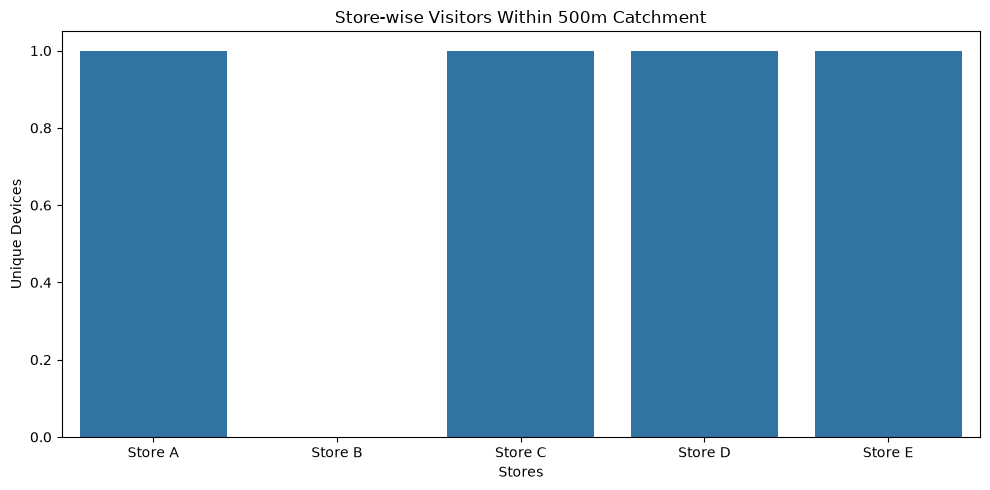

In [20]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=store_summary,
    x="StoreName",
    y="Unique_Visitors_500m"
)

plt.title("Store-wise Visitors Within 500m Catchment")
plt.xlabel("Stores")
plt.ylabel("Unique Devices")
plt.tight_layout()
plt.show()

In [21]:
os.makedirs("outputs", exist_ok=True)

risk_df.to_csv(
    "outputs/store_cannibalization_risk.csv",
    index=False
)

store_summary.to_csv(
    "outputs/store_catchment_summary.csv",
    index=False
)

overlap_df.to_csv(
    "outputs/store_pair_overlap.csv",
    index=False
)

print("All analysis files saved successfully!")

All analysis files saved successfully!


In [22]:
print("Generated Output Files:")

for file in os.listdir("outputs"):
    print("✔", file)

Generated Output Files:
✔ store_cannibalization_risk.csv
✔ store_catchment_summary.csv
✔ store_pair_overlap.csv


In [23]:
import os

print("Notebook directory:")
print(os.getcwd())

print("\nNotebook files:")
print(os.listdir())

Notebook directory:
C:\Users\HP\GeoPulse--Hyper-Local-Retail-Mobility-Analytics

Notebook files:
['.git', '.gitignore', '.ipynb_checkpoints', '.venv', '02_gps_data_quality_eda.ipynb', '03_spatial_catchment_analysis.ipynb', '03_store_data_validation.ipynb', 'data', 'dbt', 'GeoPulse_Week1_GPS_Analysis.ipynb', 'notebooks', 'outputs', 'README.md', 'reports', 'sql', 'src', 'tests', 'Untitled.ipynb']


In [24]:
import os

print(os.getcwd())

C:\Users\HP\GeoPulse--Hyper-Local-Retail-Mobility-Analytics


In [25]:
import os

os.chdir(r"C:\Users\HP\GeoPulse--Hyper-Local-Retail-Mobility-Analytics")

print(os.getcwd())

C:\Users\HP\GeoPulse--Hyper-Local-Retail-Mobility-Analytics


In [26]:
import os

print("Current folder:", os.getcwd())
print("Notebook files in this folder:")

for root, dirs, files in os.walk(r"C:\Users\HP"):
    dirs[:] = [d for d in dirs if d not in [".git", "site-packages"]]
    for file in files:
        if file.endswith(".ipynb"):
            print(os.path.join(root, file))

Current folder: C:\Users\HP\GeoPulse--Hyper-Local-Retail-Mobility-Analytics
Notebook files in this folder:
C:\Users\HP\04_store_cannibalization_analysis.ipynb
C:\Users\HP\project.ipynb
C:\Users\HP\Untitled.ipynb
C:\Users\HP\Untitled1.ipynb
C:\Users\HP\Untitled2.ipynb
C:\Users\HP\Untitled3.ipynb
C:\Users\HP\Untitled4.ipynb
C:\Users\HP\Untitled5.ipynb
C:\Users\HP\Untitled6.ipynb
C:\Users\HP\Untitled7.ipynb
C:\Users\HP\.ipynb_checkpoints\04_store_cannibalization_analysis-checkpoint.ipynb
C:\Users\HP\.ipynb_checkpoints\project-checkpoint.ipynb
C:\Users\HP\.ipynb_checkpoints\Untitled-checkpoint.ipynb
C:\Users\HP\.ipynb_checkpoints\Untitled1-checkpoint.ipynb
C:\Users\HP\.ipynb_checkpoints\Untitled2-checkpoint.ipynb
C:\Users\HP\.ipynb_checkpoints\Untitled3-checkpoint.ipynb
C:\Users\HP\.ipynb_checkpoints\Untitled4-checkpoint.ipynb
C:\Users\HP\.ipynb_checkpoints\Untitled5-checkpoint.ipynb
C:\Users\HP\.ipynb_checkpoints\Untitled6-checkpoint.ipynb
C:\Users\HP\.ipynb_checkpoints\Untitled7-checkpoi